<a href="https://colab.research.google.com/github/sivakumarcse2568/DS-ML-AI-Tasks/blob/main/Linear_Regression_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Startup Profit Prediction
import pandas as pd
data = pd.read_csv("/content/50_Startups.csv")
data.head()


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [2]:
data.shape

(50, 5)

In [3]:
data.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [5]:
data.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [6]:
data.isnull().sum()

,0
R&D Spend,0
Administration,0
Marketing Spend,0
State,0
Profit,0


In [7]:
data.duplicated().sum()

np.int64(0)

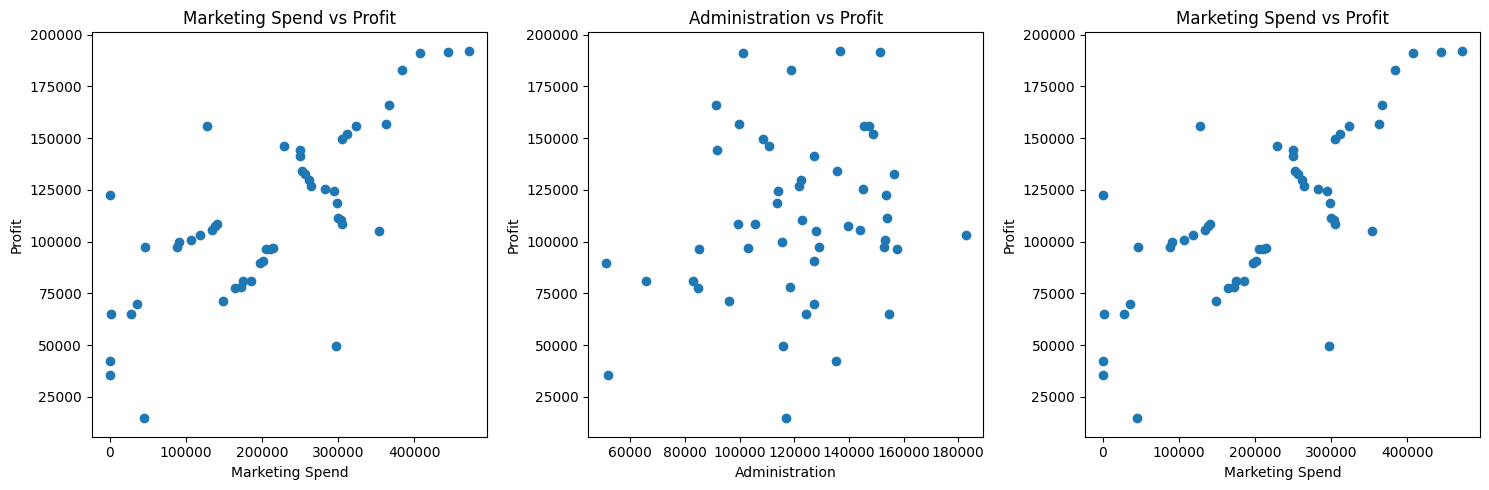

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(data['Marketing Spend'], data['Profit'])
plt.xlabel('Marketing Spend')
plt.ylabel('Profit')
plt.title('Marketing Spend vs Profit')

plt.subplot(1, 3, 2)
plt.scatter(data['Administration'], data['Profit'])
plt.xlabel('Administration')
plt.ylabel('Profit')
plt.title('Administration vs Profit')

plt.subplot(1, 3, 3)
plt.scatter(data['Marketing Spend'], data['Profit'])
plt.xlabel('Marketing Spend')
plt.ylabel('Profit')
plt.title('Marketing Spend vs Profit')

plt.tight_layout()
plt.show()


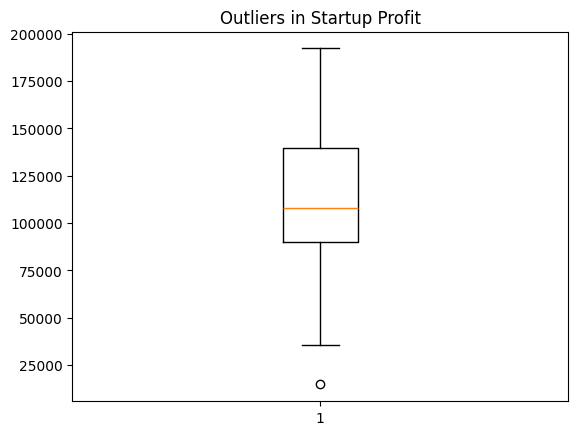

In [9]:
#Outlier Detection
#Outlier in StartUp Profit
plt.boxplot(data['Profit'])
plt.title('Outliers in Startup Profit')
plt.show()

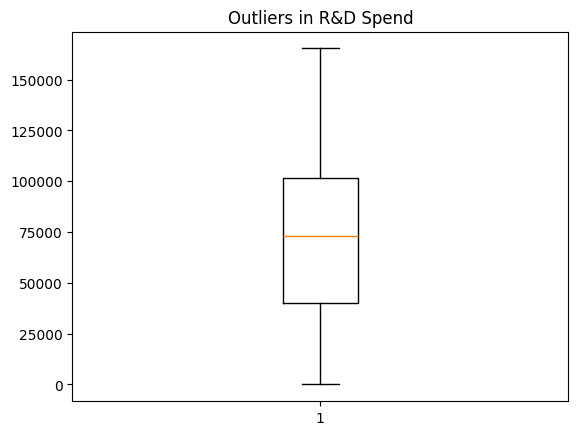

In [10]:
#Outlier in R&D Expenditure
plt.boxplot(data['R&D Spend'])
plt.title('Outliers in R&D Spend')
plt.show()

In [11]:
#Simple Linear Regression
#Build a Simple Linear Regression model.
#Feature Selection
x = data[['R&D Spend']]
y = data['Profit']

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.85,random_state=42)
print(x_train.count())

R&D Spend    42
dtype: int64


In [14]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)
y_pred = lr.predict(x_test)
print(y_pred)

[127723.95927094  82063.21522539 102089.90667338  49968.61513512
 130001.07972168  49577.08751806 113484.51565169 104371.69284674]


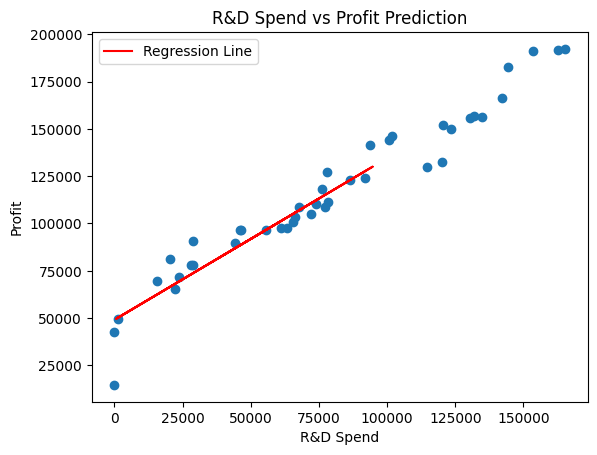

In [15]:
#Visualization

plt.scatter(x_train,y_train)
plt.plot(x_test,y_pred,color='red',label='Regression Line')
plt.xlabel('R&D Spend')
plt.ylabel('Profit')
plt.title('R&D Spend vs Profit Prediction')
plt.legend()
plt.show()

In [20]:
#Multiple Linear Regression
#Build a Multiple Linear Regression model.
#Feature Selection
data = data.drop('State',axis=1)
x = data.drop('Profit',axis=1)
y = data['Profit']

In [21]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.85,random_state=42)

lr = LinearRegression()
lr.fit(x_train,y_train)
y_pred = lr.predict(x_test)
print(y_pred)

[126947.41188763  84898.3796512   99859.47135603  47280.71580646
 129206.73354016  51690.55439508 109892.83682595 101574.80065258]


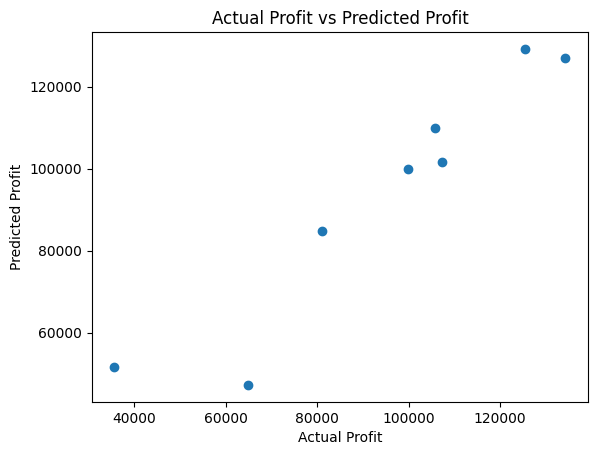

In [23]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Profit')
plt.ylabel('Predicted Profit')
plt.title('Actual Profit vs Predicted Profit')
plt.show()

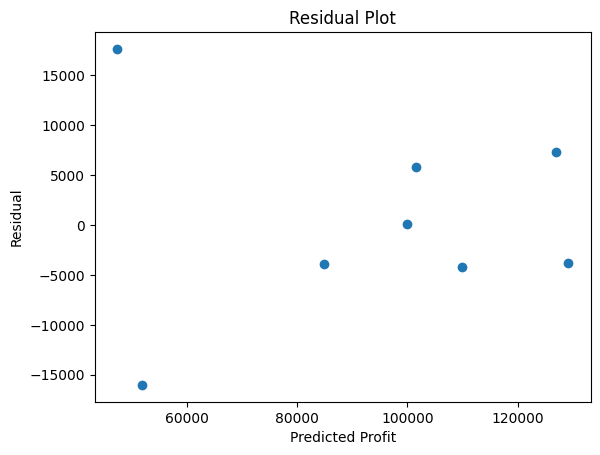

In [24]:
residual = y_test - y_pred
plt.scatter(y_pred, residual)
plt.xlabel('Predicted Profit')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.show()

In [25]:
#Encode the state feature.
#Interpret the regression coefficients.
#Predict profit for a startup with given expenditure values.
new_data = pd.DataFrame({'R&D Spend':[100000],'Administration':[120000],'Marketing Spend':[200000]})
prediction = lr.predict(new_data)
print("Predicted Startup Profit:",prediction[0])

Predicted Startup Profit: 133259.29882622135


In [ ]:
#	Evaluate the model using suitable metrics.
#Check multicollinearity using VIF.
#Recommend how a startup could use the model when planning expenditure.
